<a href="https://colab.research.google.com/github/ssamirbaba39/python-workshop-basics/blob/Session_1/Linear_Regression_Ridge_Lasso_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Machine Learning - Lab Assignment
## Linear Regression, Ridge and Lasso

**Name:** ___________________   **Group:** __________  **Date:** __________

This notebook completes Tasks 1–13 using Python 3, NumPy, pandas, Matplotlib, and scikit-learn.

## Task 1 — Generate the dataset
Set the random seed to 42. Generate experience first, then independent noise, and calculate salary.

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

np.random.seed(42)

YearsOfExperience = np.random.randint(2, 21, size=500)
intercept = 60000
slope = (200000 - 60000) / (20 - 2)

noise = np.random.normal(0, 10000, size=500)
Salary = intercept + slope * YearsOfExperience + noise

df = pd.DataFrame({
    "YearsOfExperience": YearsOfExperience,
    "Salary": Salary
})

display(df.head())
print("Dataset shape:", df.shape)

,YearsOfExperience,Salary
0,8,115037.780010
1,16,182309.972927
2,12,156442.408989
3,9,144753.562169
4,8,130798.818454


Dataset shape: (500, 2)


## Task 2 — Explore the dataset
`describe()` gives summary statistics. `isnull().sum()` counts missing values. Correlation measures the strength and direction of the linear relationship.

In [2]:
print("Shape:", df.shape)
print("\nSummary statistics:")
display(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

correlation = df["YearsOfExperience"].corr(df["Salary"])
print("\nCorrelation:", correlation)

Shape: (500, 2)

Summary statistics:


,YearsOfExperience,Salary
count,500.000000,500.000000
mean,10.616000,142570.011096
std,5.662922,44935.263058
min,2.000000,54881.134555
25%,5.750000,104426.300731
50%,10.000000,139865.032545
75%,16.000000,182341.125962
max,20.000000,241879.376204



Missing values:
YearsOfExperience    0
Salary               0
dtype: int64

Correlation: 0.975058457607618


## Task 3 — Plot the data

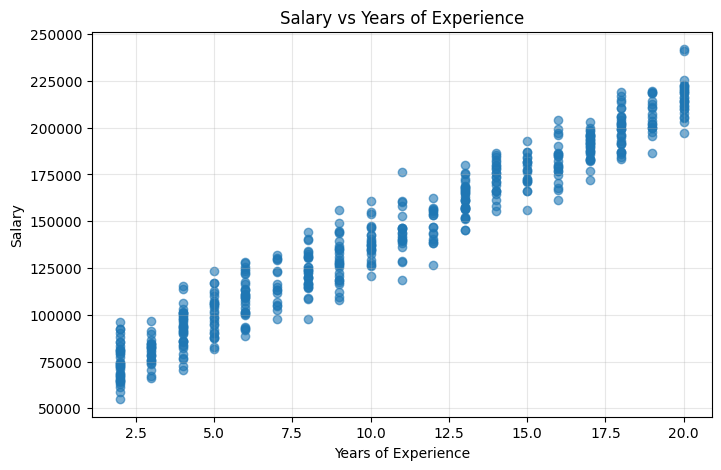

In [16]:
plt.figure(figsize=(8, 5))
plt.scatter(df["YearsOfExperience"], df["Salary"], alpha=0.6)
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Salary vs Years of Experience")
plt.grid(True, alpha=0.3)
plt.show()

## Task 4 — Split the dataset
`X` must be two-dimensional for scikit-learn. The split uses 80% training data and 20% test data.

In [19]:
X = df[["YearsOfExperience"]]
y = df["Salary"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train size:", X_train.shape)
print("X_test size:", X_test.shape)
print("y_train size:", y_train.shape)
print("y_test size:", y_test.shape)

X_train size: (400, 1)
X_test size: (100, 1)
y_train size: (400,)
y_test size: (100,)


## Task 5 — Train linear regression
The model estimates the slope (coefficient) and intercept from the training set. R² is calculated on both sets.

In [24]:
lr = LinearRegression()
lr.fit(X_train, y_train)

print("Slope / coefficient:", lr.coef_[0])
print("Intercept:", lr.intercept_)
print("Training R2:", lr.score(X_train, y_train))
print("Test R2:", lr.score(X_test, y_test))

Slope / coefficient: 7696.612923052044
Intercept: 60961.340880280564
Training R2: 0.9488372177019488
Test R2: 0.9573704756930141


## Task 6 — Evaluate linear regression
MAE is the mean absolute error, MSE is the mean squared error, RMSE is the square root of MSE, and R² compares the model with a mean-based reference.

In [26]:
y_pred_lr = lr.predict(X_test)

mae_lr = mean_absolute_error(y_test, y_pred_lr)
mse_lr = mean_squared_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mse_lr)
r2_lr = r2_score(y_test, y_pred_lr)

print("Linear Regression Test MAE:", mae_lr)
print("Linear Regression Test MSE:", mse_lr)
print("Linear Regression Test RMSE:", rmse_lr)
print("Linear Regression Test R2:", r2_lr)

pairs = pd.DataFrame({
    "Actual Salary": y_test.to_numpy(),
    "Predicted Salary": y_pred_lr
})
display(pairs.head())

Linear Regression Test MAE: 7905.114728709239
Linear Regression Test MSE: 93933277.37947103
Linear Regression Test RMSE: 9691.918147584152
Linear Regression Test R2: 0.9573704756930141


,Actual Salary,Predicted Salary
0,123631.230350,107141.018419
1,139775.630647,122534.244265
2,93184.812446,107141.018419
3,166740.803478,161017.308880
4,174587.183981,184107.147649


## Task 7 — Compare with a baseline
The baseline predicts the mean salary from the training set for every test example. The training mean is used to avoid test-data leakage.

In [7]:
training_mean_salary = y_train.mean()
y_pred_baseline = np.full(shape=len(y_test), fill_value=training_mean_salary)

mae_baseline = mean_absolute_error(y_test, y_pred_baseline)
rmse_baseline = np.sqrt(mean_squared_error(y_test, y_pred_baseline))

print("Training mean salary:", training_mean_salary)
print("Baseline test MAE:", mae_baseline)
print("Baseline test RMSE:", rmse_baseline)
print("Linear Regression test MAE:", mae_lr)
print("Linear Regression test RMSE:", rmse_lr)

Training mean salary: 142353.02254155593
Baseline test MAE: 40444.95787424255
Baseline test RMSE: 46953.769510036946
Linear Regression test MAE: 7905.114728709239
Linear Regression test RMSE: 9691.918147584152


## Task 8 — Plot predictions and residuals
Residual = actual salary − predicted salary. The fitted line is drawn across the range of test experience values.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


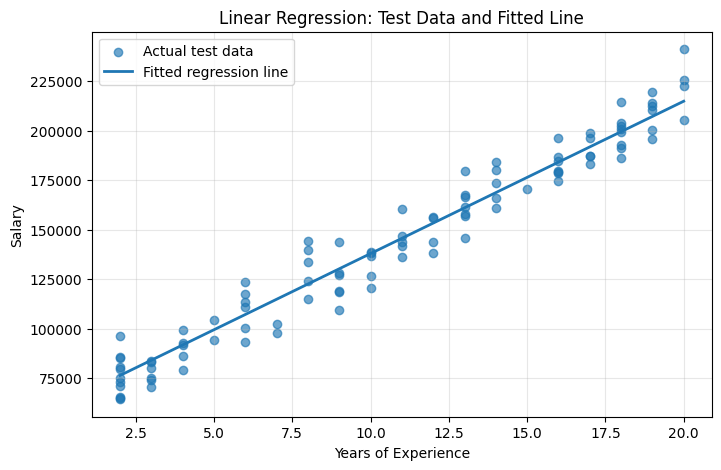

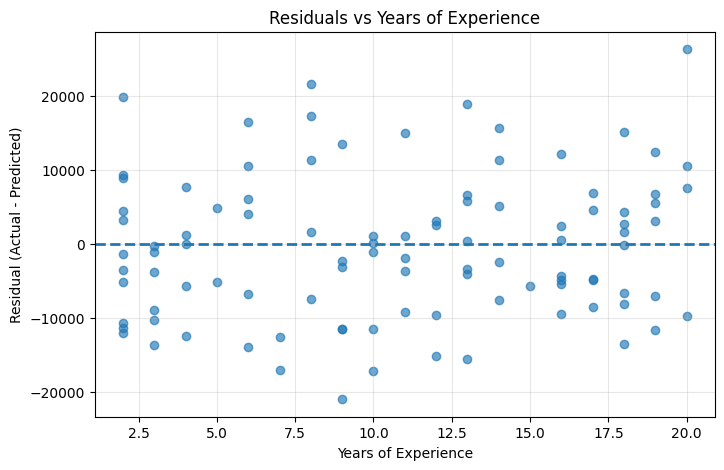

In [8]:
# (a) Test data and fitted regression line
plt.figure(figsize=(8, 5))
plt.scatter(X_test["YearsOfExperience"], y_test, alpha=0.65, label="Actual test data")
x_line = np.linspace(X_test["YearsOfExperience"].min(),
                     X_test["YearsOfExperience"].max(), 200).reshape(-1, 1)
y_line = lr.predict(x_line)
plt.plot(x_line, y_line, linewidth=2, label="Fitted regression line")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Linear Regression: Test Data and Fitted Line")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# (b) Residuals
residuals = y_test.to_numpy() - y_pred_lr
plt.figure(figsize=(8, 5))
plt.scatter(X_test["YearsOfExperience"], residuals, alpha=0.65)
plt.axhline(0, linestyle="--", linewidth=2)
plt.xlabel("Years of Experience")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residuals vs Years of Experience")
plt.grid(True, alpha=0.3)
plt.show()

## Task 9 — Predict new salaries
Use the trained linear regression model to predict salaries for 5, 10, and 15 years of experience.

In [9]:
new_experience = pd.DataFrame({"YearsOfExperience": [5, 10, 15]})
new_salary_predictions = lr.predict(new_experience)

new_predictions = pd.DataFrame({
    "YearsOfExperience": new_experience["YearsOfExperience"],
    "PredictedSalary": new_salary_predictions
})
display(new_predictions)

,YearsOfExperience,PredictedSalary
0,5,99444.405496
1,10,137927.470111
2,15,176410.534726


## Task 10 — Standardize the feature
Fit `StandardScaler` on `X_train` only, then transform both train and test features. The target `y` is not scaled.

In [10]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training feature mean:", X_train_scaled.mean())
print("Scaled training feature standard deviation:", X_train_scaled.std())

Scaled training feature mean: 1.4210854715202004e-16
Scaled training feature standard deviation: 1.0


## Task 11 — Train Ridge regression
Ridge uses L2 regularization. Fit models for alpha 10 and 100. Because the feature is standardized, report the coefficient in standardized-feature units.

In [11]:
ridge_results = {}
for alpha in [10, 100]:
    ridge = Ridge(alpha=alpha)
    ridge.fit(X_train_scaled, y_train)
    pred = ridge.predict(X_test_scaled)
    ridge_results[alpha] = {
        "model": ridge,
        "coefficient": ridge.coef_[0],
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
        "predictions": pred
    }

ridge_table = pd.DataFrame([
    {
        "Alpha": alpha,
        "Coefficient (scaled feature)": values["coefficient"],
        "Test MAE": values["MAE"],
        "Test RMSE": values["RMSE"],
        "Test R2": values["R2"]
    }
    for alpha, values in ridge_results.items()
])
display(ridge_table)

ridge_final = ridge_results[10]

,Alpha,Coefficient (scaled feature),Test MAE,Test RMSE,Test R2
0,10,42156.503108,8084.461348,9876.931577,0.955727
1,100,34568.332548,11308.369994,13937.846116,0.911838


## Task 12 — Train Lasso regression
Lasso uses L1 regularization. Use `max_iter=20000` for all specified alpha values.

In [23]:
lasso_results = {}
for alpha in [1000, 10000, 50000]:
    lasso = Lasso(alpha=alpha, max_iter=20000)
    lasso.fit(X_train_scaled, y_train)
    pred = lasso.predict(X_test_scaled)
    lasso_results[alpha] = {
        "model": lasso,
        "coefficient": lasso.coef_[0],
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
        "predictions": pred
    }

lasso_table = pd.DataFrame([
    {
        "Alpha": alpha,
        "Coefficient (scaled feature)": values["coefficient"],
        "Test MAE": values["MAE"],
        "Test RMSE": values["RMSE"],
        "Test R2": values["R2"]
    }
    for alpha, values in lasso_results.items()
])
display(lasso_table)

lasso_final = lasso_results[1000]

,Alpha,Coefficient (scaled feature),Test MAE,Test RMSE,Test R2
0,1000,42210.415685,8074.651463,9864.608230,0.955838
1,10000,33210.415685,12287.962687,14988.535076,0.898045
2,50000,0.000000,40444.957874,46953.769510,-0.000534


## Task 13 — Compare the models
Compare the baseline, linear regression, Ridge (alpha=10), and Lasso (alpha=1000) using the same test set.

In [21]:
comparison = pd.DataFrame([
    {
        "Model": "Mean baseline",
        "Test MAE": mae_baseline,
        "Test RMSE": rmse_baseline,
        "Test R2": r2_score(y_test, y_pred_baseline)
    },
    {
        "Model": "Linear Regression",
        "Test MAE": mae_lr,
        "Test RMSE": rmse_lr,
        "Test R2": r2_lr
    },
    {
        "Model": "Ridge (alpha=10)",
        "Test MAE": ridge_final["MAE"],
        "Test RMSE": ridge_final["RMSE"],
        "Test R2": ridge_final["R2"]
    },
    {
        "Model": "Lasso (alpha=1000)",
        "Test MAE": lasso_final["MAE"],
        "Test RMSE": lasso_final["RMSE"],
        "Test R2": lasso_final["R2"]
    }
])

display(comparison.round(3))

best_mae_model = comparison.loc[comparison["Test MAE"].idxmin(), "Model"]
best_rmse_model = comparison.loc[comparison["Test RMSE"].idxmin(), "Model"]
print(f"Lowest test MAE: {best_mae_model}")
print(f"Lowest test RMSE: {best_rmse_model}")

,Model,Test MAE,Test RMSE,Test R2
0,Mean baseline,40444.958,46953.770,-0.001
1,Linear Regression,7905.115,9691.918,0.957
2,Ridge (alpha=10),8084.461,9876.932,0.956
3,Lasso (alpha=1000),8074.651,9864.608,0.956


Lowest test MAE: Linear Regression
Lowest test RMSE: Linear Regression


### Discussion (two sentences)
Compare the test MAE and RMSE values: lower values indicate smaller prediction errors. Compare test R² as well: a value closer to 1 indicates that the model explains more of the variation in test salaries; use the table above to identify which model performs best on this generated dataset.